# Lab 8 (Classwork): Model Selection
### Cross-Validation and Hyper-parameter Tuning

In this lab you will learn how to **estimate how well a model works on new data** and how to **pick the best model and its settings** without cheating with the test set.

---
## Part 0 — Setup

In [18]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.model_selection import (
    train_test_split, cross_val_score, cross_validate,
    KFold, StratifiedKFold, ShuffleSplit, StratifiedShuffleSplit,
    GroupKFold, StratifiedGroupKFold, GroupShuffleSplit, LeaveOneGroupOut,
    RepeatedStratifiedKFold, LeaveOneOut, TimeSeriesSplit,
    GridSearchCV, RandomizedSearchCV,
)
# Successive halving is still "experimental" in scikit-learn, so we must enable it first
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingGridSearchCV, HalvingRandomSearchCV

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import mean_squared_error, make_scorer, recall_score

from scipy.stats import randint, loguniform

warnings.filterwarnings("ignore")
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (7, 4)

import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


### Helper 1: an "Auto-like" dataset

The lecture uses the **Auto** data from the ISLR book (predict `mpg` from `horsepower`, 392 cars).
To avoid downloading files, we **simulate** a dataset with the same shape and the same curved relationship.

(392, 1) (392,)


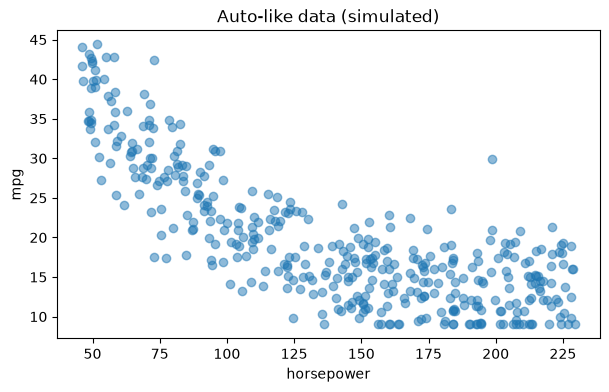

In [19]:
def make_auto_like(n=392, seed=1):
    # Simulated 'Auto' data: mpg is a curved (quadratic) function of horsepower + noise.
    rng = np.random.RandomState(seed)
    horsepower = rng.uniform(46, 230, n)
    mpg = 56.9 - 0.466 * horsepower + 0.00123 * horsepower**2 + rng.normal(0, 4.3, n)
    mpg = np.clip(mpg, 9, 47)
    return horsepower.reshape(-1, 1), mpg

X_auto, y_auto = make_auto_like()
print(X_auto.shape, y_auto.shape)

plt.scatter(X_auto, y_auto, alpha=0.5)
plt.xlabel("horsepower"); plt.ylabel("mpg"); plt.title("Auto-like data (simulated)")
plt.show()

### Helper 2: a polynomial regression model

We use a **pipeline**: scale `horsepower` → create polynomial terms → linear regression.
A higher `degree` means a **more complex** model.

In [20]:
def poly_model(degree):
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression())

poly_model(3)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",3
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


---
## Part 1 — Training error vs Test error

- **Training error**: error on the data the model was trained on.
- **Test error**: error on **new** data that the model has never seen.

The training error usually **underestimates** the test error. When the model is too complex for the amount of data, it **overfits** (low bias, high variance).

Below we train polynomial models with degree 1 to 12 on only **30 cars**, and test on the other cars.

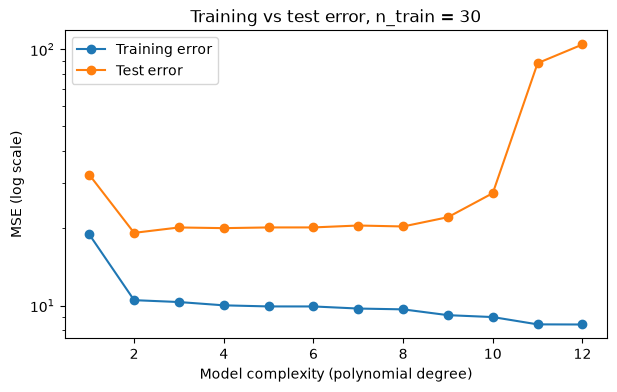

degree,1,2,3,4,5,6,7,8,9,10,11,12
train_MSE,18.952,10.501,10.325,10.023,9.925,9.923,9.738,9.668,9.176,9.021,8.448,8.438
test_MSE,32.404,19.224,20.178,20.056,20.182,20.187,20.535,20.360,22.130,27.463,88.320,104.441


In [21]:
X_tr, X_te, y_tr, y_te = train_test_split(X_auto, y_auto, train_size=30, random_state=0)

degrees = range(1, 13)
train_mse, test_mse = [], []
for d in degrees:
    model = poly_model(d).fit(X_tr, y_tr)
    train_mse.append(mean_squared_error(y_tr, model.predict(X_tr)))
    test_mse.append(mean_squared_error(y_te, model.predict(X_te)))

plt.plot(degrees, train_mse, "o-", label="Training error")
plt.plot(degrees, test_mse, "o-", label="Test error")
plt.yscale("log")
plt.xlabel("Model complexity (polynomial degree)"); plt.ylabel("MSE (log scale)")
plt.title("Training vs test error, n_train = 30")
plt.legend(); plt.show()

pd.DataFrame({"degree": degrees, "train_MSE": train_mse, "test_MSE": test_mse}).set_index("degree").T

### "Can very large datasets solve this problem?"
Repeat the experiment above with **`train_size=300`** and plot both curves again.

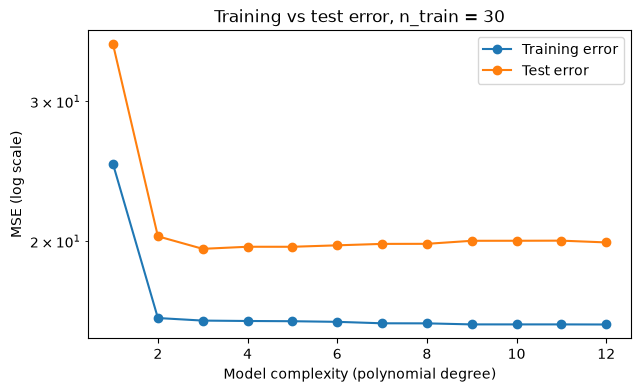

degree,1,2,3,4,5,6,7,8,9,10,11,12
train_MSE,24.999,16.001,15.883,15.864,15.854,15.825,15.759,15.756,15.708,15.708,15.708,15.704
test_MSE,35.373,20.281,19.557,19.676,19.674,19.757,19.840,19.843,20.019,20.021,20.027,19.924


In [ ]:
# Hint: copy the cell above and change train_size=30 to train_size=300

X_tr, X_te, y_tr, y_te = train_test_split(X_auto, y_auto, train_size=300, random_state=0)

degrees = range(1, 13)
train_mse, test_mse = [], []
for d in degrees:
    model = poly_model(d).fit(X_tr, y_tr)
    train_mse.append(mean_squared_error(y_tr, model.predict(X_tr)))
    test_mse.append(mean_squared_error(y_te, model.predict(X_te)))

plt.plot(degrees, train_mse, "o-", label="Training error")
plt.plot(degrees, test_mse, "o-", label="Test error")
plt.yscale("log")
plt.xlabel("Model complexity (polynomial degree)"); plt.ylabel("MSE (log scale)")
plt.title("Training vs test error, n_train = 30")
plt.legend(); plt.show()

pd.DataFrame({"degree": degrees, "train_MSE": train_mse, "test_MSE": test_mse}).set_index("degree").T

**Questions**
1. Why is the training error lower than the test error?
2. With 300 training points, what happens to the gap between the two curves at high degrees? Does more data solve overfitting completely?

*Your answer:*

---
## Part 2 — Validation set approach

We split the data into three parts:

`training set` (fit the model) → `validation set` (choose hyper-parameters) → `test set` (final evaluation, used **once**)

### 2.1 Choose `n_neighbors` for KNN (Breast Cancer data)

In [23]:
X_bc, y_bc = datasets.load_breast_cancer(return_X_y=True)
print("Breast cancer:", X_bc.shape, "| class counts:", np.bincount(y_bc))

X_trainval, X_test, y_trainval, y_test = train_test_split(X_bc, y_bc, test_size=0.4, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.2, random_state=0)
print("train:", X_train.shape, " val:", X_val.shape, " test:", X_test.shape)

Breast cancer: (569, 30) | class counts: [212 357]
train: (272, 30)  val: (69, 30)  test: (228, 30)


best validation score: 0.884
best n_neighbors: 3
test-set score: 0.939


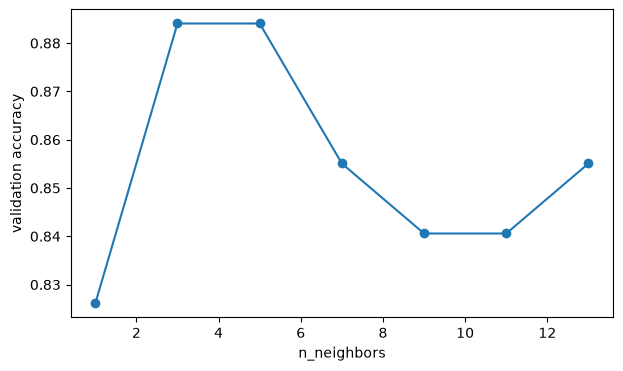

In [24]:
neighbors = np.arange(1, 15, 2)
val_scores = []
for k in neighbors:
    knn = KNeighborsClassifier(n_neighbors=k)   # use k here (not a fixed number!)
    knn.fit(X_train, y_train)
    val_scores.append(knn.score(X_val, y_val))

best_k = neighbors[np.argmax(val_scores)]
print(f"best validation score: {np.max(val_scores):.3f}")
print(f"best n_neighbors: {best_k}")

# Retrain on train+validation with the best k, then evaluate ONCE on the test set
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_trainval, y_trainval)
print(f"test-set score: {knn.score(X_test, y_test):.3f}")

plt.plot(neighbors, val_scores, "o-")
plt.xlabel("n_neighbors"); plt.ylabel("validation accuracy"); plt.show()

### How stable is the validation set approach?
Repeat the code above for 5 different validation splits: `random_state` = 0, 1, 2, 3, 4 in the **second** `train_test_split` (keep the test set the same).
For each seed, print the best `n_neighbors`, the best validation score and the test score.

================================================== seed:0 ==================================================
train: (272, 30)  val: (69, 30)  test: (228, 30)
best validation score: 0.884
best n_neighbors: 3
test-set score: 0.939


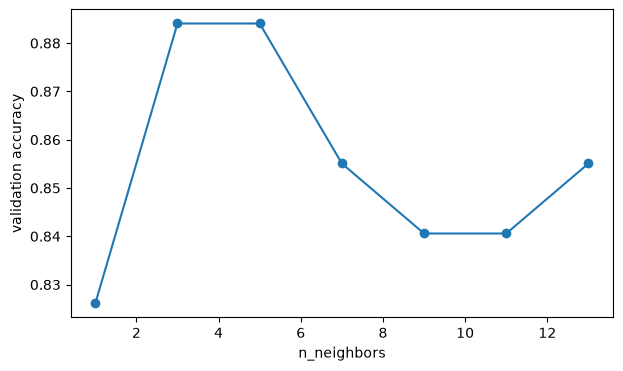

================================================== seed:1 ==================================================
train: (272, 30)  val: (69, 30)  test: (228, 30)
best validation score: 0.913
best n_neighbors: 3
test-set score: 0.917


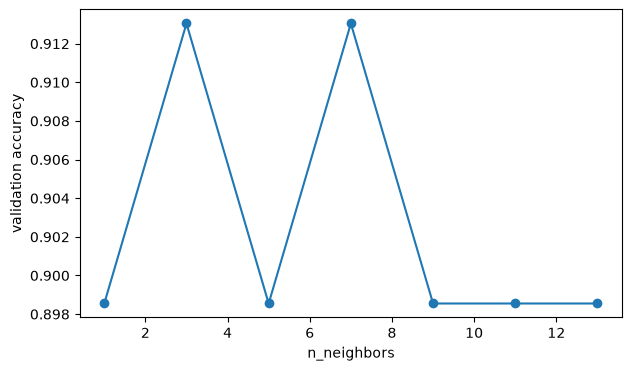

================================================== seed:2 ==================================================
train: (272, 30)  val: (69, 30)  test: (228, 30)
best validation score: 0.957
best n_neighbors: 11
test-set score: 0.925


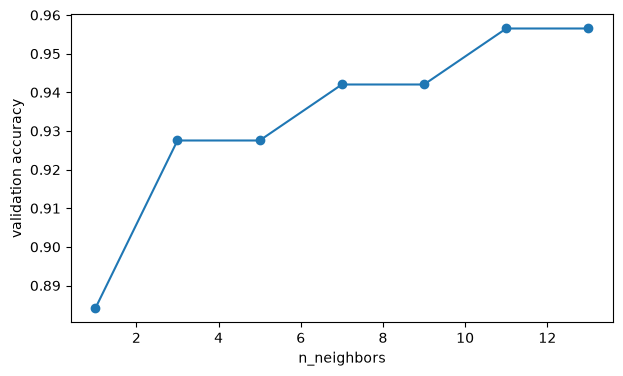

================================================== seed:3 ==================================================
train: (272, 30)  val: (69, 30)  test: (228, 30)
best validation score: 0.928
best n_neighbors: 13
test-set score: 0.956


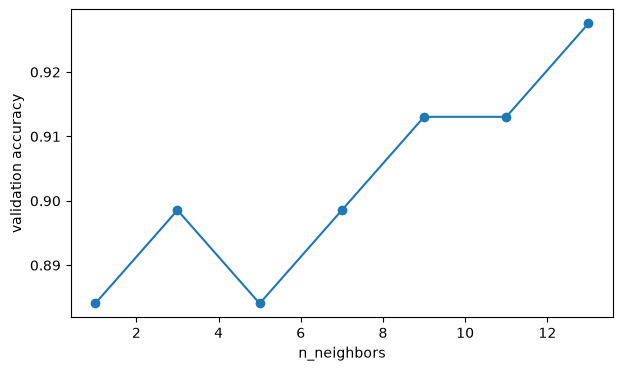

================================================== seed:4 ==================================================
train: (272, 30)  val: (69, 30)  test: (228, 30)
best validation score: 0.986
best n_neighbors: 9
test-set score: 0.917


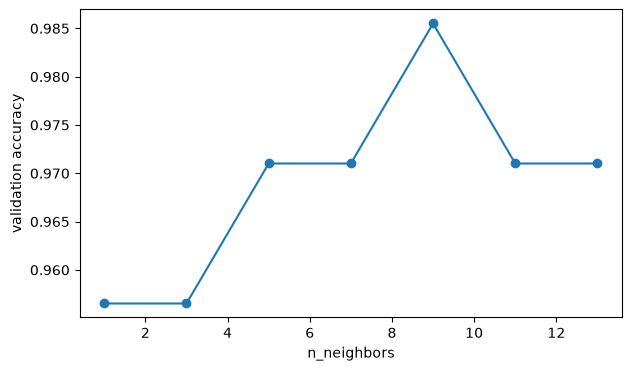

In [25]:
# YOUR CODE HERE
for seed in range(5):
    print(f"{'='*50} seed:{seed} {'='*50}")
    # 1) split X_trainval into X_train, X_val using random_state=seed
    X_trainval, X_test, y_trainval, y_test = train_test_split(X_bc, y_bc, test_size=0.4, random_state=seed)
    X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.2, random_state=seed)
    print("train:", X_train.shape, " val:", X_val.shape, " test:", X_test.shape)
    # 2) find the best k on the validation set
    neighbors = np.arange(1, 15, 2)
    val_scores = []
    for k in neighbors:
        knn = KNeighborsClassifier(n_neighbors=k)   # use k here (not a fixed number!)
        knn.fit(X_train, y_train)
        val_scores.append(knn.score(X_val, y_val))

    best_k = neighbors[np.argmax(val_scores)]
    print(f"best validation score: {np.max(val_scores):.3f}")
    print(f"best n_neighbors: {best_k}")
    # 3) retrain on X_trainval and score on X_test
    knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_trainval, y_trainval)
    print(f"test-set score: {knn.score(X_test, y_test):.3f}")

    plt.plot(neighbors, val_scores, "o-")
    plt.xlabel("n_neighbors"); plt.ylabel("validation accuracy"); plt.show()
    # pass

**Question:** Is the "best" `n_neighbors` always the same? What does this tell you about the validation set approach?

*Your answer:*
One validation splits gives a different error curve each time you re-split the data.

- With one validation split, the score depends on which samples are belong to the validation set resulting a lucky split looks good and an unlucky split looks bad.
- Cross-validation repeats the split several times and averages the results, so one lucky or unlucky split can't decide the answer on its own.

---
## Part 3 — Leave-One-Out Cross-Validation (LOOCV)

LOOCV uses **one** observation for validation and the other $n-1$ for training, and repeats this $n$ times:

$$CV_{(n)} = \frac{1}{n}\sum_{i=1}^{n} MSE_i$$

Each left-out point is either predicted correctly (score 1) or wrongly (score 0), and the LOOCV accuracy is the average of these $n$ scores.

### 3.2 LOOCV on the Breast Cancer data
We go back to the **same problem as Part 2**: choose `n_neighbors` for KNN.
We use the same `X_trainval` (341 samples) and the same values of k. The test set is still **not touched**.

Instead of one validation split, LOOCV uses every one of the 341 samples as a validation point once.

Number of LOO splits: 341
LOOCV score shape: (341,)
First 20 LOO scores for k=5: [1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 1. 0. 1. 1. 1. 1. 1. 0. 1. 1.]
X_bc shape: (569, 30), X_trainval shape: (341, 30)
LOOCV time for 7 values of k: 1.5 s
best n_neighbors: 7 | LOOCV accuracy: 0.912


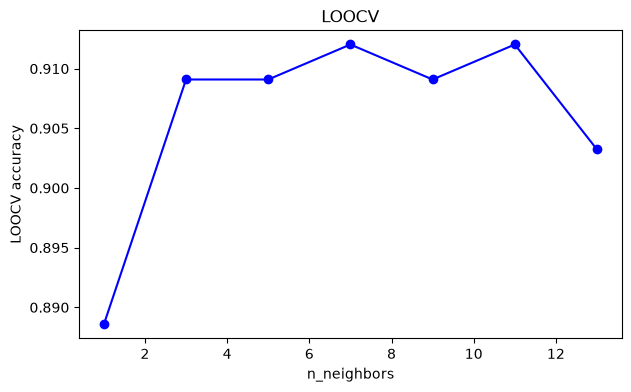

In [ ]:
# Re-create the Part 2 split (random_state=0) so we use exactly the same data
X_trainval, X_test, y_trainval, y_test = train_test_split(X_bc, y_bc, test_size=0.4, random_state=0)
neighbors = np.arange(1, 15, 2)

loo = LeaveOneOut()
print(f"X_bc shape: {X_bc.shape}, X_trainval shape: {X_trainval.shape}")
print("Number of LOO splits:", loo.get_n_splits(X_trainval))

start = time.time()
loocv_acc = []
for k in neighbors:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_trainval, y_trainval, cv=loo)
    loocv_acc.append(scores.mean())
    if k == 5:
        print(f"LOOCV score shape: {scores.shape}")
        print("First 20 LOO scores for k=5:", scores[:20])   # every score is 0 or 1
loo_time = time.time() - start

best_k_loo = neighbors[np.argmax(loocv_acc)]
print(f"LOOCV time for {len(neighbors)} values of k: {loo_time:.1f} s")
print(f"best n_neighbors: {best_k_loo} | LOOCV accuracy: {max(loocv_acc):.3f}")

plt.plot(neighbors, loocv_acc, "o-", color="blue")
plt.xlabel("n_neighbors"); plt.ylabel("LOOCV accuracy"); plt.title("LOOCV"); plt.show()

---
## Part 4 — k-fold Cross-Validation

In [37]:
kf = KFold(n_splits=5, shuffle=True, random_state=0)
n = len(y_trainval)
cv_k = 0.0

for k, (train_idx, val_idx) in enumerate(kf.split(X_trainval)):
    # 1) fit KNeighborsClassifier(n_neighbors=5) on the training indices
    model = KNeighborsClassifier(n_neighbors=5).fit(X_trainval[train_idx], y_trainval[train_idx])
    # 2) compute Acc_k on the validation indices (hint: model.score)
    acc_k = model.score(X_trainval[val_idx], y_trainval[val_idx])
    n_k = len(val_idx)
    # 3) add (n_k / n) * Acc_k to cv_k
    cv_k += (n_k / n) * acc_k
    print(f"fold {k}: n_k_train = {len(train_idx)}, n_k_val = {n_k}, Acc_k = {acc_k:.3f}")

print("Manual CV(5) =", cv_k)

fold 0: n_k_train = 272, n_k_val = 69, Acc_k = 0.884
fold 1: n_k_train = 273, n_k_val = 68, Acc_k = 0.912
fold 2: n_k_train = 273, n_k_val = 68, Acc_k = 0.912
fold 3: n_k_train = 273, n_k_val = 68, Acc_k = 0.897
fold 4: n_k_train = 273, n_k_val = 68, Acc_k = 0.926
Manual CV(5) = 0.9061583577712611


In [32]:
# Compare with scikit-learn (use the SAME kf object)
scores = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_trainval, y_trainval, cv=kf)
print("cross_val_score scores:", scores)
print("cross_val_score mean  =", scores.mean())

cross_val_score scores: [0.884 0.912 0.912 0.897 0.926]
cross_val_score mean  = 0.9062233589087809


> The two numbers are almost the same. They are not exactly equal because 341 is not a multiple of 5 (one fold has 69 points, the others 68): `cross_val_score(...).mean()` gives every fold the same weight, while the formula weights each fold by $n_k/n$.

### 4.2 One validation split vs LOOCV vs 10-fold CV
Now we put the three methods side by side, on the **same data** and the **same values of k**:
- **One validation split** (Part 2), repeated with 5 different seeds
- **LOOCV** (Part 3), which is always the same
- **10-fold CV**, repeated with 5 different shuffles

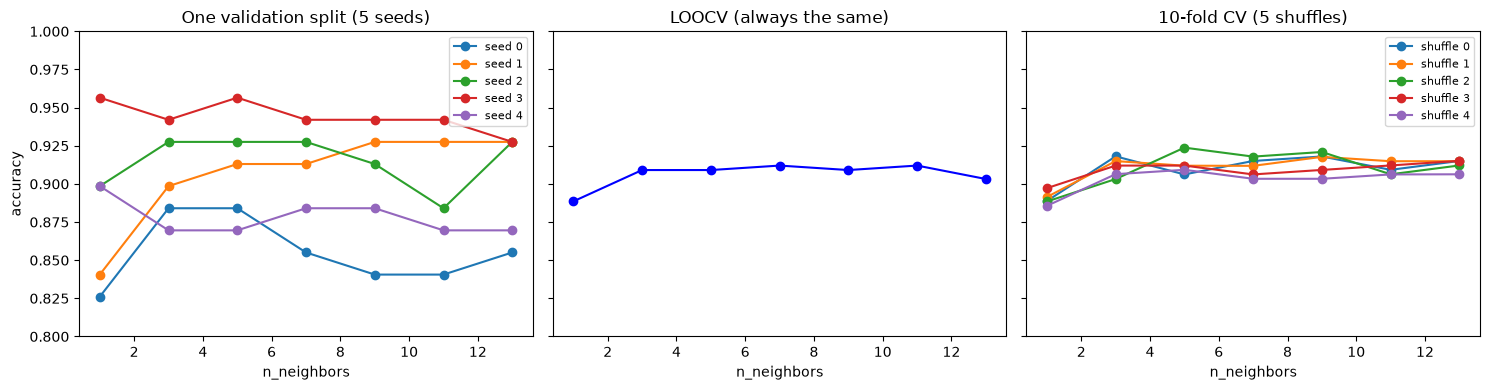

,lowest score,highest score,avg. spread between runs,best k in each run,time for one run (s)
One validation split,0.826,0.957,0.093,"[3, 9, 3, 1, 1]",NaN
LOOCV,0.889,0.912,0.000,[7],1.538
10-fold CV,0.886,0.924,0.013,"[3, 9, 5, 13, 5]",0.058


In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

# (a) One validation split, 5 different seeds
split_curves, split_best = [], []
for seed in range(5):
    X_tr, X_va, y_tr, y_va = train_test_split(X_trainval, y_trainval, test_size=0.2, random_state=seed)
    acc = [KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr).score(X_va, y_va) for k in neighbors]
    split_curves.append(acc); split_best.append(neighbors[np.argmax(acc)])
    axes[0].plot(neighbors, acc, "o-", label=f"seed {seed}")
axes[0].set_title("One validation split (5 seeds)"); axes[0].set_ylabel("accuracy"); axes[0].legend(fontsize=8)

# (b) LOOCV (from Part 3)
axes[1].plot(neighbors, loocv_acc, "o-", color="blue")
axes[1].set_title("LOOCV (always the same)")

# (c) 10-fold CV, 5 different shuffles
kfold_curves, kfold_best, kfold_times = [], [], []
for rep in range(5):
    kf10 = KFold(n_splits=10, shuffle=True, random_state=rep)
    start = time.time()
    acc = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_trainval, y_trainval, cv=kf10).mean()
           for k in neighbors]
    kfold_times.append(time.time() - start)
    kfold_curves.append(acc); kfold_best.append(neighbors[np.argmax(acc)])
    axes[2].plot(neighbors, acc, "o-", label=f"shuffle {rep}")
axes[2].set_title("10-fold CV (5 shuffles)"); axes[2].legend(fontsize=8)

for ax in axes:
    ax.set_xlabel("n_neighbors"); ax.set_ylim(0.8, 1.0)
plt.tight_layout(); plt.show()

summary_cv = pd.DataFrame({
    "lowest score": [np.min(split_curves), np.min(loocv_acc), np.min(kfold_curves)],
    "highest score": [np.max(split_curves), np.max(loocv_acc), np.max(kfold_curves)],
    "avg. spread between runs": [np.ptp(split_curves, axis=0).mean(), 0.0, np.ptp(kfold_curves, axis=0).mean()],
    "best k in each run": [split_best, [best_k_loo], kfold_best],
    "time for one run (s)": [np.nan, loo_time, np.mean(kfold_times)],
}, index=["One validation split", "LOOCV", "10-fold CV"])
summary_cv

> **avg. spread between runs** = for each k, the difference between the highest and the lowest score over the 5 runs, averaged over all k. A small spread means the method gives almost the same answer every time.

In [40]:
kfold_mean = np.mean(kfold_curves, axis=0)      # average the 5 runs for each k
kfold_std  = np.std(kfold_curves, axis=0)

print(pd.DataFrame({"n_neighbors": neighbors,
                    "mean 10-fold acc": kfold_mean,
                    "std over 5 runs": kfold_std}).round(4))

best_k_10fold = neighbors[np.argmax(kfold_mean)]
print("Best n_neighbors (10-fold, averaged over 5 runs):", best_k_10fold)

# Gold standard: retrain on ALL train+val data with the chosen k, then test ONCE
final_knn = KNeighborsClassifier(n_neighbors=best_k_10fold).fit(X_trainval, y_trainval)
print(f"Test-set accuracy: {final_knn.score(X_test, y_test):.3f}")

   n_neighbors  mean 10-fold acc  std over 5 runs
0            1             0.890            0.004
1            3             0.911            0.005
2            5             0.913            0.006
3            7             0.911            0.005
4            9             0.914            0.006
5           11             0.910            0.003
6           13             0.913            0.003
Best n_neighbors (10-fold, averaged over 5 runs): 9
Test-set accuracy: 0.965


**How to choose `n_neighbors` (k):** for each k, average its scores, then pick the k with the **highest average**.
- **One validation split (5 seeds):** average of 5 split scores per k (one score per seed).
- **LOOCV:** average of 341 scores per k (one score per left-out sample, each 0 or 1). Only one run is needed because LOOCV has no randomness.
- **10-fold CV (5 seeds):** average of 50 fold scores per k (5 runs × 10 folds).

> Note: in practice, the validation set approach uses **one** split only. We repeat it with 5 seeds here just to show how much the result changes from split to split.

---
## Part 5 — Cross-validation iterators in scikit-learn

### 5.1 Visualise how each iterator splits the data
100 random points, **3 classes** with uneven sizes (10 %, 30 %, 60 %) and **10 groups** of equal size.

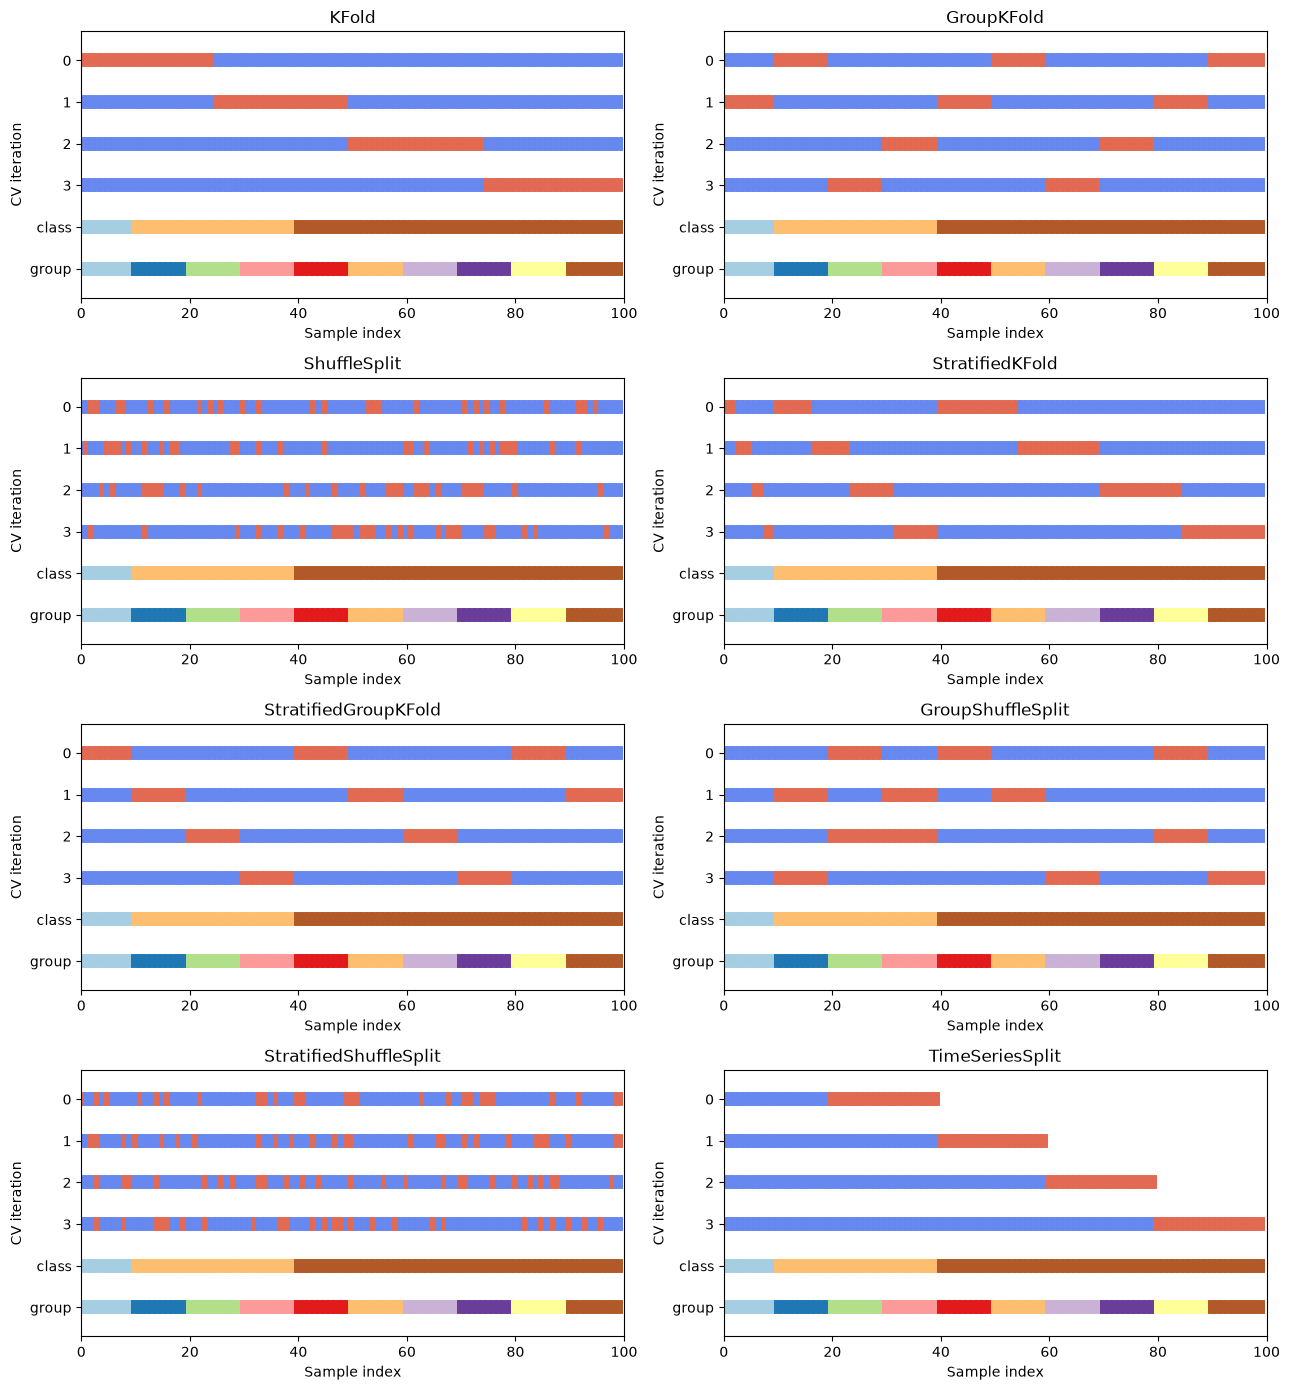

In [42]:
cmap_data = plt.cm.Paired
cmap_cv = plt.cm.coolwarm

def plot_cv_indices(cv, X, y, group, ax, lw=10):
    # Draw the train (blue) / test (red) indices of every CV split, plus the class and group rows.
    splits = list(cv.split(X=X, y=y, groups=group))
    for ii, (tr, tt) in enumerate(splits):
        indices = np.full(len(X), np.nan)
        indices[tt] = 1
        indices[tr] = 0
        ax.scatter(range(len(indices)), [ii + 0.5] * len(indices), c=indices, marker="_",
                   lw=lw, cmap=cmap_cv, vmin=-0.2, vmax=1.2)
    n = len(splits)
    ax.scatter(range(len(X)), [n + 0.5] * len(X), c=y, marker="_", lw=lw, cmap=cmap_data)
    ax.scatter(range(len(X)), [n + 1.5] * len(X), c=group, marker="_", lw=lw, cmap=cmap_data)
    ax.set(yticks=np.arange(n + 2) + 0.5, yticklabels=list(range(n)) + ["class", "group"],
           xlabel="Sample index", ylabel="CV iteration", ylim=[n + 2.2, -0.2], xlim=[0, len(X)])
    ax.set_title(type(cv).__name__)

rng = np.random.RandomState(1338)
X_demo = rng.randn(100, 10)
y_demo = np.hstack([[c] * int(100 * p) for c, p in enumerate([0.1, 0.3, 0.6])])
groups_demo = np.hstack([[g] * 10 for g in range(10)])

cvs = [KFold(4), GroupKFold(4), ShuffleSplit(4, test_size=0.25, random_state=0),
       StratifiedKFold(4), StratifiedGroupKFold(4), GroupShuffleSplit(4, test_size=0.25, random_state=0),
       StratifiedShuffleSplit(4, test_size=0.25, random_state=0), TimeSeriesSplit(4)]

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for cv, ax in zip(cvs, axes.ravel()):
    plot_cv_indices(cv, X_demo, y_demo, groups_demo, ax)
plt.tight_layout(); plt.show()

### Summary

| Iterator | Shuffles the data? | Keeps class proportions? | Keeps groups together? | Typical use |
|---|---|---|---|---|
| KFold | No (only if `shuffle=True`) | No | No | Regression, i.i.d. data |
| StratifiedKFold | No (only if `shuffle=True`) | **Yes** | No | Classification, imbalanced classes (default for classifiers) |
| ShuffleSplit | Yes (random test set each time, may overlap) | No | No | Many random train/test splits, large data |
| StratifiedShuffleSplit | Yes | **Yes** | No | Random splits for classification |
| GroupKFold | No | No | **Yes** | Several samples per patient/person |
| StratifiedGroupKFold | Optional | Tries to | **Yes** | Groups + imbalanced classes |
| GroupShuffleSplit | Yes | No | **Yes** | Random splits with groups |
| TimeSeriesSplit | No (keeps time order) | No | No | Time series: train on past, test on future |


`ShuffleSplit:` k-fold with shuffle (KFold(5, shuffle=True, random_state=0))
- First, the order of all 10 samples is mixed randomly, once.
- Then they are cut into 5 folds, and these folds stay fixed for all 5 rounds:

### 5.2 Using different CV generators

In [43]:
knn_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
generators = {
    "KFold(5)": KFold(n_splits=5),
    "StratifiedKFold(5, shuffle)": StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
    "ShuffleSplit(20, train .4, test .3)": ShuffleSplit(n_splits=20, train_size=0.4, test_size=0.3, random_state=0),
    "RepeatedStratifiedKFold(5 x 10)": RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0),
}
rows = []
for name, cv in generators.items():
    s = cross_val_score(knn_pipe, X_bc, y_bc, cv=cv)
    rows.append({"generator": name, "n_scores": len(s), "mean": s.mean(), "std": s.std()})
pd.DataFrame(rows)

,generator,n_scores,mean,std
0,KFold(5),5,0.960,0.017
1,"StratifiedKFold(5, shuffle)",5,0.965,0.021
2,"ShuffleSplit(20, train .4, test .3)",20,0.963,0.015
3,RepeatedStratifiedKFold(5 x 10),50,0.967,0.016


> More scores (ShuffleSplit, Repeated…) give a **more reliable mean** and show the spread, but cost more fits.

### 5.3 Cross-validation with groups
Imagine **40 patients**, each visited the clinic **12 times**. Each patient has a fixed diagnosis (0/1). Visits from the same patient are very similar to each other.

We want to know: *how well does the model work for a **new** patient?*

In [44]:
def make_patient_data(n_patients=40, visits=12, signal=4.0, seed=0):
    rng = np.random.RandomState(seed)
    patient_id = np.repeat(np.arange(n_patients), visits)
    label = rng.randint(0, 2, n_patients)                     # one diagnosis per patient
    patient_profile = rng.normal(0, 2, size=(n_patients, 5))   # each patient looks different
    X = patient_profile[patient_id] + rng.normal(0, 0.5, size=(len(patient_id), 5))
    X[:, :2] += signal * label[patient_id][:, None]            # the real (weaker) signal
    return X, label[patient_id], patient_id

X_pat, y_pat, pid = make_patient_data()
print(X_pat.shape, "patients:", len(np.unique(pid)))

knn_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
s_kf = cross_val_score(knn_pipe, X_pat, y_pat, cv=KFold(5, shuffle=True, random_state=0))
s_gkf = cross_val_score(knn_pipe, X_pat, y_pat, cv=GroupKFold(5), groups=pid)
print(f"KFold (shuffle): {s_kf.mean():.3f}")
print(f"GroupKFold     : {s_gkf.mean():.3f}")

(480, 5) patients: 40
KFold (shuffle): 0.979
GroupKFold     : 0.787


### 5.4 Time Series Split
`TimeSeriesSplit` always trains on the **past** and tests on the **future**. Each training set is a superset of the previous one.

In [ ]:
X_small = np.arange(12).reshape(-1, 1)
tscv = TimeSeriesSplit(n_splits=4)
for i, (tr, te) in enumerate(tscv.split(X_small)):
    print(f"Fold {i}: train={tr}  test={te}")

Now a monthly **temperature anomaly** series from 1850 to 2024. It is **simulated** to look like the global temperature data.

In [ ]:
def make_temperature_series(seed=0):
    rng = np.random.RandomState(seed)
    dates = pd.date_range("1850-01-01", "2024-12-01", freq="MS")
    t = np.arange(len(dates))
    trend = -0.35 + 6e-7 * np.maximum(t - 1200, 0) ** 2      # warming after ~1950
    season = 0.1 * np.sin(2 * np.pi * t / 12)
    noise = np.zeros(len(t)); e = rng.normal(0, 0.12, len(t))
    for i in range(1, len(t)):
        noise[i] = 0.6 * noise[i - 1] + e[i]                     # today looks like yesterday
    return pd.DataFrame({"Date": dates, "Mean": trend + season + noise})

df_temp = make_temperature_series()
print(df_temp.shape)
df_temp.head()

In [ ]:
plt.figure(figsize=(12, 3))
plt.plot(df_temp["Date"], df_temp["Mean"])
plt.title("Monthly temperature anomaly (simulated)"); plt.ylabel("°C"); plt.show()

n_splits = 4
tscv = TimeSeriesSplit(n_splits=n_splits)
fig, axes = plt.subplots(n_splits, 1, figsize=(12, 9), sharex=True)
for i, (tr, te) in enumerate(tscv.split(df_temp)):
    axes[i].plot(df_temp.loc[tr, "Date"], df_temp.loc[tr, "Mean"], color="C0", label="Train")
    axes[i].plot(df_temp.loc[te, "Date"], df_temp.loc[te, "Mean"], color="C1", label="Test")
    axes[i].set_title(f"Fold {i + 1}"); axes[i].legend(loc="upper left")
plt.tight_layout(); plt.show()

---
## Part 6 — `cross_val_score` scoring and `cross_validate`

**Model selection** (slide 4) also means choosing **between different algorithms**. We compare KNN, Logistic Regression and Random Forest on the breast cancer data.

### 6.1 Change the metric with `scoring`

In [ ]:
knn_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

scores = cross_val_score(knn_pipe, X_bc, y_bc, cv=5)                       # default: accuracy
print("accuracy :", scores, f"-> {scores.mean():.3f} ± {scores.std():.3f}")

scores = cross_val_score(knn_pipe, X_bc, y_bc, cv=5, scoring="f1_macro")   # macro F1
print("f1_macro :", scores, f"-> {scores.mean():.3f} ± {scores.std():.3f}")

accuracy : [0.965 0.956 0.982 0.956 0.965] -> 0.965 ± 0.010
f1_macro : [0.963 0.953 0.981 0.952 0.962] -> 0.962 ± 0.011


### 6.2 Several metrics at once with `cross_validate`
`cross_validate` returns a dictionary with `fit_time`, `score_time`, the test scores and (optionally) the train scores. Metrics can be strings or custom scorers made with `make_scorer`.

In [47]:
scoring = {
    "acc": "accuracy",
    "roc_auc": "roc_auc",
    "rec_macro": make_scorer(recall_score, average="macro"),   # a custom scorer
}
res = cross_validate(knn_pipe, X_bc, y_bc, cv=5, scoring=scoring, return_train_score=True)
print(sorted(res.keys()))
pd.DataFrame(res)

['fit_time', 'score_time', 'test_acc', 'test_rec_macro', 'test_roc_auc', 'train_acc', 'train_rec_macro', 'train_roc_auc']


,fit_time,score_time,test_acc,train_acc,test_roc_auc,train_roc_auc,test_rec_macro,train_rec_macro
0,1.443e-03,0.029,0.965,0.976,0.997,0.997,0.963,0.969
1,1.708e-03,0.006,0.956,0.974,0.983,0.999,0.946,0.966
2,5.689e-04,0.003,0.982,0.971,0.999,0.997,0.976,0.964
3,1.093e-03,0.003,0.956,0.974,0.984,0.998,0.940,0.968
4,1.039e-03,0.003,0.965,0.976,0.995,0.998,0.967,0.970


### ✍️ Exercise 6.1 — Which algorithm should we select?
Use `cross_validate` with `StratifiedKFold(5, shuffle=True, random_state=0)`, `scoring=["accuracy", "f1_macro", "roc_auc"]` and `return_train_score=True` for the three models below.
Build **one summary table** with the mean of: `fit_time`, `test_accuracy`, `train_accuracy`, `test_f1_macro`, `test_roc_auc`.

In [48]:
models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=0),
}

In [49]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
summary = []
for name, model in models.items():
    r = cross_validate(model, X_bc, y_bc, cv=cv5, scoring=["accuracy", "f1_macro", "roc_auc"],
                       return_train_score=True)
    summary.append({"model": name,
                    "fit_time": r["fit_time"].mean(),
                    "train_accuracy": r["train_accuracy"].mean(),
                    "test_accuracy": r["test_accuracy"].mean(),
                    "test_accuracy_std": r["test_accuracy"].std(),
                    "test_f1_macro": r["test_f1_macro"].mean(),
                    "test_roc_auc": r["test_roc_auc"].mean()})
pd.DataFrame(summary).set_index("model")

,fit_time,train_accuracy,test_accuracy,test_accuracy_std,test_f1_macro,test_roc_auc
model,,,,,,
KNN,0.001,0.978,0.965,0.021,0.962,0.981
LogisticRegression,0.004,0.988,0.979,0.014,0.977,0.995
RandomForest,0.053,1.000,0.965,0.015,0.962,0.992


**Questions**
1. Which model would you select? Use at least two numbers from your table.
2. Which model has the largest gap between train and test accuracy? What does that mean?

**Sample answer:**
1. **Logistic Regression**: highest test accuracy (~0.97–0.98) and ROC-AUC (~0.99+), small standard deviation, and it is fast to train.
2. **Random Forest**: train accuracy = 1.00 but test ≈ 0.96. It fits the training data perfectly, i.e. it **overfits** a bit (it still generalises well). We should compare models by the **test** (validation) score, never the train score.

---
## Part 7 — Hyper-parameter tuning

### 7.1 Grid search "by hand"

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X_bc, y_bc, stratify=y_bc, random_state=0)

neighbors = np.arange(1, 30, 2)
cv_scores = []
for k in neighbors:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_scores.append(cross_val_score(pipe, X_train, y_train, cv=10).mean())

best_k = neighbors[np.argmax(cv_scores)]
print(f"best cross-validation score: {np.max(cv_scores):.3f} with n_neighbors = {best_k}")

best cross-validation score: 0.974 with n_neighbors = 9


### 7.2 `GridSearchCV`
`GridSearchCV` does the loop above for us, then **refits** the best model on the whole training set.

> We put the `StandardScaler` **inside a pipeline**. Then, in every CV split, the scaler is fitted only on the training folds. If we scaled all data first, information from the validation folds would **leak** into training.
> To tune a step of a pipeline, use the name `<step>__<parameter>`, e.g. `knn__n_neighbors`.

In [51]:
pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
param_grid = {"knn__n_neighbors": np.arange(1, 30, 2)}

grid = GridSearchCV(pipe, param_grid=param_grid, cv=10, return_train_score=True)
grid.fit(X_train, y_train)

print(f"best mean cross-validation score: {grid.best_score_:.3f}")
print(f"best parameters: {grid.best_params_}")
print(f"test-set score: {grid.score(X_test, y_test):.3f}")

best mean cross-validation score: 0.974
best parameters: {'knn__n_neighbors': np.int64(9)}
test-set score: 0.951


In [52]:
# 1) the result log
results = pd.DataFrame(grid.cv_results_)
print(results.shape)
results[["param_knn__n_neighbors", "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]

(15, 31)


,param_knn__n_neighbors,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,1,1.000,0.960,0.028,8
1,3,0.986,0.970,0.018,5
2,5,0.978,0.972,0.014,2
3,7,0.977,0.972,0.020,2
4,9,0.978,0.974,0.022,1
5,11,0.976,0.972,0.020,4
6,13,0.974,0.970,0.023,6
7,15,0.968,0.962,0.021,7
8,17,0.967,0.953,0.031,13
9,19,0.963,0.951,0.030,15


In [53]:
# 2) the best results and 3) extra information
print("best_index_    :", grid.best_index_)
print("best_estimator_:", grid.best_estimator_)
print("refit_time_    :", grid.refit_time_)
print("n_splits_      :", grid.n_splits_)
print("scorer_        :", grid.scorer_)

best_index_    : 4
best_estimator_: Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=np.int64(9)))])
refit_time_    : 0.0003597736358642578
n_splits_      : 10
scorer_        : Pipeline.score


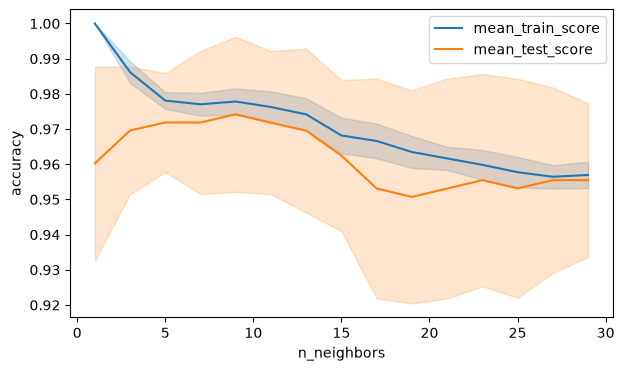

In [54]:
# Plot train and validation score vs n_neighbors (slide 46)
k = results["param_knn__n_neighbors"].astype(int)
for split, color in [("train", "C0"), ("test", "C1")]:
    m, s = results[f"mean_{split}_score"], results[f"std_{split}_score"]
    plt.plot(k, m, color=color, label=f"mean_{split}_score")
    plt.fill_between(k, m - s, m + s, color=color, alpha=0.2)
plt.xlabel("n_neighbors"); plt.ylabel("accuracy"); plt.legend(); plt.show()

At `n_neighbors = 1` the train score is 1.0 but the validation score is lower → **overfitting** (high variance). At large `n_neighbors` both scores go down together → the model becomes too smooth → **underfitting** (high bias). The best value is in between, where the validation score is highest.

### 7.3 `RandomizedSearchCV`
Grid search tries **every** combination. Randomized search tries only `n_iter` random combinations drawn from distributions.

`GridSearchCV` tries **every combination** in the grid. In Part 7.3 of the lab:

```python
param_grid = {"n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15],   # 8 values
              "weights": ["uniform", "distance"],            # 2 values
              "p": [1, 2]}                                    # 2 values
```
That's 8 × 2 × 2 = **32 combinations**. With `cv=5`, each combination is trained 5 times, so **160 fits**.

Add one more parameter with 10 values and it becomes 320 combinations and 1,600 fits. The grid grows very fast.

## What RandomizedSearchCV does
Instead of trying everything, it **tries only `n_iter` random combinations** and keeps the best one.

```python
param_dist = {"n_neighbors": randint(1, 30),           # any whole number from 1 to 29
              "weights": ["uniform", "distance"],      # pick one of these
              "p": [1, 2]}                              # pick one of these

random_search = RandomizedSearchCV(knn, param_distributions=param_dist,
                                   n_iter=10, cv=5, random_state=42)
```

Step by step:
1. **Draw a random combination.** For example `n_neighbors=17, weights="distance", p=1`.
   - For a **list**, it picks one value from the list.
   - For a **distribution** like `randint(1, 30)`, it draws a random number from that range. The value doesn't have to be in a fixed list, so it can try values like 12 or 17 that our grid never had.
2. **Run 5-fold CV** for that combination and record the average score.
3. **Repeat** until it has tried `n_iter=10` combinations.
4. **Pick the combination with the highest average CV score**, then retrain it on all the training data (refit). After that, `best_params_`, `best_score_` and `best_estimator_` work exactly as in GridSearchCV.

So it makes 10 × 5 = **50 fits** (+1 refit) instead of 160.

`random_state=42` fixes which combinations are drawn, so you get the same result every time you run it.

In [58]:
knn = KNeighborsClassifier()

param_grid = {"n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15],
              "weights": ["uniform", "distance"],
              "p": [1, 2]}                         # 1 = Manhattan, 2 = Euclidean
param_dist = {"n_neighbors": randint(1, 30),
              "weights": ["uniform", "distance"],
              "p": [1, 2]}

start = time.time()
grid_search = GridSearchCV(knn, param_grid=param_grid, cv=5, scoring="accuracy", n_jobs=-1).fit(X_iris, y_iris)
grid_time = time.time() - start

start = time.time()
random_search = RandomizedSearchCV(knn, param_distributions=param_dist, n_iter=10, cv=5,
                                   scoring="accuracy", random_state=42, n_jobs=-1).fit(X_iris, y_iris)
random_time = time.time() - start

print(f"Grid   : best {grid_search.best_params_}  acc = {grid_search.best_score_:.4f}  time = {grid_time:.2f}s")
print(f"Random : best {random_search.best_params_}  acc = {random_search.best_score_:.4f}  time = {random_time:.2f}s")

Grid   : best {'n_neighbors': 11, 'p': 2, 'weights': 'distance'}  acc = 0.9867  time = 1.96s
Random : best {'n_neighbors': 12, 'p': 2, 'weights': 'distance'}  acc = 0.9867  time = 0.03s


| | Combinations tried | Fits | Best found | Accuracy | Time |
|---|---|---|---|---|---|
| GridSearchCV | 32 (all) | 160 | n_neighbors=11, distance, p=2 | 0.987 | 1.55 s |
| RandomizedSearchCV | 10 (random) | 50 | n_neighbors=12, distance, p=2 | 0.987 | 0.10 s |

Randomized search reached **the same accuracy with about one third of the fits.**

### 7.4 Successive Halving (slide 51)
**Start wide, finish narrow:**
1. Train **many** candidates on a **small** amount of data.
2. Keep only the best fraction (1/`factor`).
3. Give the survivors **more** data.
4. Repeat until one or a few candidates are left.

We tune a Random Forest on the **Digits** dataset (1,797 images of handwritten digits, 64 features).

In [60]:
X_dig, y_dig = datasets.load_digits(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_dig, y_dig, test_size=0.25, stratify=y_dig, random_state=42)

rf_grid = {"n_estimators": [25, 50, 100],
           "max_depth": [5, 10, None],
           "max_features": ["sqrt", "log2"],
           "min_samples_leaf": [1, 3]}          # 3 x 3 x 2 x 2 = 36 candidates

start = time.time()
halving = HalvingGridSearchCV(RandomForestClassifier(random_state=0), rf_grid, cv=5, factor=3,
                              random_state=0, n_jobs=-1).fit(Xd_train, yd_train)
halving_time = time.time() - start

print(f"time: {halving_time:.1f} s")
print("candidates per iteration:", halving.n_candidates_)
print("samples per iteration   :", halving.n_resources_)
print("min resources per itration :", halving.min_resources_)
print("max resources per itration :", halving.max_resources_)
print("best params:", halving.best_params_)
print(f"best CV score: {halving.best_score_:.4f} | test score: {halving.score(Xd_test, yd_test):.4f}")

time: 3.2 s
candidates per iteration: [36, 12, 4]
samples per iteration   : [100, 300, 900]
min resources per itration : 100
max resources per itration : 1347
best params: {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 100}
best CV score: 0.9710 | test score: 0.9756


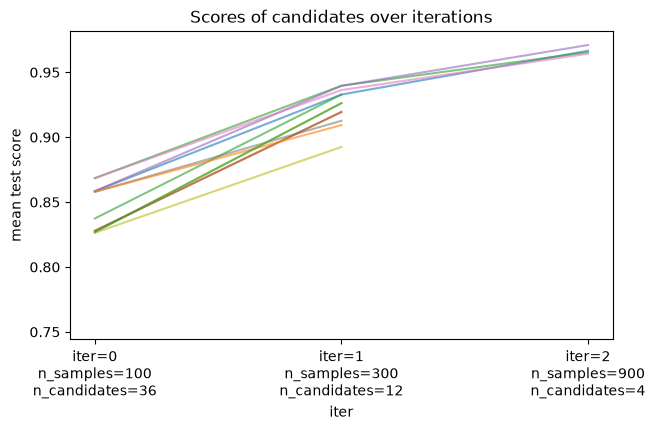

In [61]:
# Scores of candidates over iterations (like the figure on slide 51)
res = pd.DataFrame(halving.cv_results_)
res["params_str"] = res["params"].apply(str)
table = res.pivot(index="iter", columns="params_str", values="mean_test_score")
ax = table.plot(legend=False, alpha=0.6, figsize=(7, 4))
ax.set_xticks(range(len(halving.n_resources_)))
ax.set_xticklabels([f"iter={i}\nn_samples={halving.n_resources_[i]}\nn_candidates={halving.n_candidates_[i]}"
                    for i in range(len(halving.n_resources_))])
ax.set_ylabel("mean test score"); ax.set_title("Scores of candidates over iterations")
plt.show()